<a href="https://colab.research.google.com/github/chipojaya1/ISS-Economic-Distance/blob/main/Economic_distance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prepare environment and load the data

In [105]:
# define necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

In [106]:
# load wdi data as wdi from my github https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx
df = pd.read_excel('https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx?raw=true')

print("df type:", type(df))
print("df shape:", df.shape)
df.head()

df type: <class 'pandas.core.frame.DataFrame'>
df shape: (873, 5)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [107]:
# 1. Clean up potential leading/trailing whitespaces in string columns
df['Series Name'] = df['Series Name'].str.strip()
display(df.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [108]:
# 2. Define the mapping for Series Name renaming
name_mapping = {
    'GDP per capita (constant 2015 US$)': 'gdp_per_capita',
    'Inflation, GDP deflator (annual %)': 'inflation',
    'Imports of goods and services (% of GDP)': 'imports',
    'Exports of goods and services (% of GDP)': 'exports'
}

# Filter to keep only the series we are interested in and map their names
df_filtered = df[df['Series Name'].isin(name_mapping.keys())].copy()
df_filtered['Series Name'] = df_filtered['Series Name'].map(name_mapping)
display(df_filtered.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,imports,NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,exports,NE.EXP.GNFS.ZS,..
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [109]:
# 3. Clean the value column: replace '..' with NaN and convert to float
val_col = '2019 [YR2019]'
df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)
df_filtered[val_col] = pd.to_numeric(df_filtered[val_col], errors='coerce')
display(df_filtered.head())

/tmp/ipykernel_11322/3241800311.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.521480
2,Afghanistan,AFG,imports,NE.IMP.GNFS.ZS,NaN
3,Afghanistan,AFG,exports,NE.EXP.GNFS.ZS,NaN
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [110]:
# 4. Pivot from long to wide (short) format
df_wide = df_filtered.pivot(index=['Country Name', 'Country Code'], columns='Series Name', values=val_col).reset_index()

# Reset column index name
df_wide.columns.name = None

# Display the cleaned and reshaped DataFrame
print("df_wide shape:", df_wide.shape)
display(df_wide.head())

df_wide shape: (217, 6)


,Country Name,Country Code,exports,gdp_per_capita,imports,inflation
0,Afghanistan,AFG,NaN,557.861533,NaN,6.521480
1,Albania,ALB,30.936122,5072.436484,44.446006,1.000633
2,Algeria,DZA,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,ASM,61.669243,12524.016025,94.899536,1.748289
4,Andorra,AND,NaN,39346.275036,NaN,1.374754


In [111]:
# rename column Country Name to country, drop country code and mask df as wdi_df
wdi_df = df_wide.rename(columns={'Country Name': 'country'}).drop(columns=['Country Code'])
print("wdi_df shape:", wdi_df.shape)
wdi_df.head()

wdi_df shape: (217, 5)


,country,exports,gdp_per_capita,imports,inflation
0,Afghanistan,NaN,557.861533,NaN,6.521480
1,Albania,30.936122,5072.436484,44.446006,1.000633
2,Algeria,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,61.669243,12524.016025,94.899536,1.748289
4,Andorra,NaN,39346.275036,NaN,1.374754


####2. Summarize the individual sub-components of the distance measure. Report and interpret the minimum, maximum, mean, median, standard deviation for each of the sub-components and the correlation between each of these sub-components

Explore summary statistics  and correlation coefficients



In [112]:
wdi_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         217 non-null    object 
 1   exports         183 non-null    float64
 2   gdp_per_capita  208 non-null    float64
 3   imports         183 non-null    float64
 4   inflation       209 non-null    float64
dtypes: float64(4), object(1)
memory usage: 8.6+ KB


In [113]:
# Summary statistics
summary_stats = wdi_df.describe()
print("Summary Statistics:")
display(summary_stats)

Summary Statistics:


,exports,gdp_per_capita,imports,inflation
count,183.000000,208.000000,183.000000,209.000000
mean,43.059452,17544.183111,48.085723,110.387032
std,31.529306,24664.928816,28.529602,1515.376731
min,7.779936,270.411006,10.607517,-4.603271
25%,22.282452,2423.171056,28.704516,0.848015
50%,36.400882,6533.112217,41.469590,2.375860
75%,52.400877,21751.331731,58.928664,4.175673
max,206.580146,185582.668516,176.092206,21909.342668


In [114]:
# Missing data
missing_data = wdi_df.isnull().sum()
print("\nMissing Data:")
display(missing_data)


Missing Data:


,0
country,0
exports,34
gdp_per_capita,9
imports,34
inflation,8


In [115]:
# Drop any country with missing values in each of the 3 indicators
cols = ['gdp_per_capita', 'inflation', 'imports', 'exports']
wdi_df = wdi_df.dropna(subset=cols)
print("wdi_df shape:", wdi_df.shape)
wdi_df.head()

wdi_df shape: (182, 5)


,country,exports,gdp_per_capita,imports,inflation
1,Albania,30.936122,5072.436484,44.446006,1.000633
2,Algeria,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,61.669243,12524.016025,94.899536,1.748289
5,Angola,36.950082,3105.599712,23.421225,20.249856
6,Antigua and Barbuda,69.164695,18525.258891,68.373089,0.712335


In [116]:
wdi_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 182 entries, 1 to 216
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         182 non-null    object 
 1   exports         182 non-null    float64
 2   gdp_per_capita  182 non-null    float64
 3   imports         182 non-null    float64
 4   inflation       182 non-null    float64
dtypes: float64(4), object(1)
memory usage: 8.5+ KB


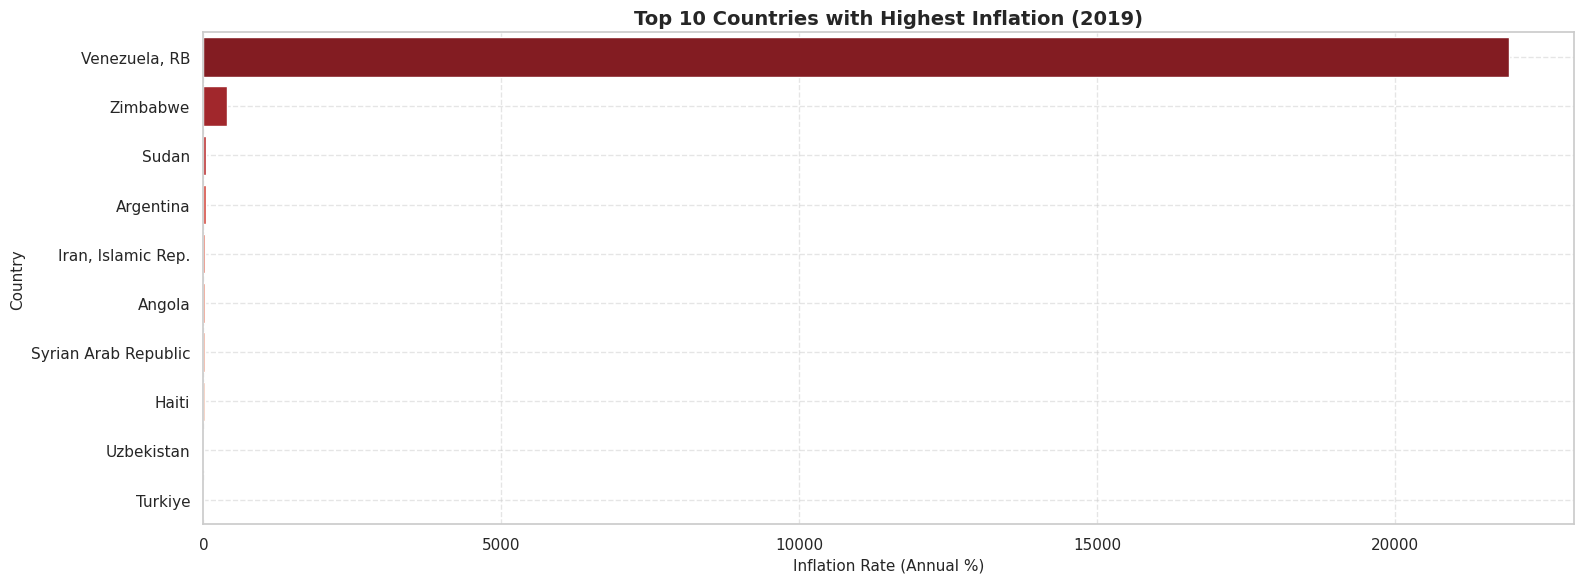

In [163]:
# Visualization for country-level inflation
fig, ax = plt.subplots(1, 1, figsize=(16, 6))

# Top 10 Countries with the Highest Inflation Rates in 2019
top_inflation = wdi_df.nlargest(10, 'inflation')
sns.barplot(x='inflation', y='country', data=top_inflation, ax=ax, hue='country', palette='Reds_r', legend=False)
ax.set_title('Top 10 Countries with Highest Inflation (2019)', fontsize=14, fontweight='bold')
ax.set_xlabel('Inflation Rate (Annual %)', fontsize=11)
ax.set_ylabel('Country', fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

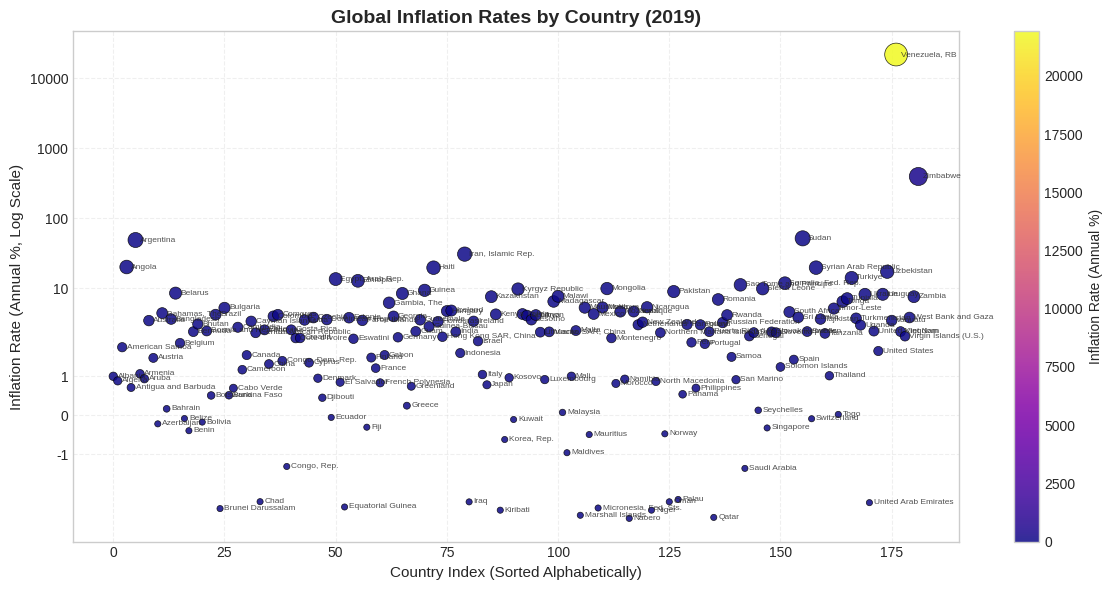

In [157]:
# Reset index to have a clean numeric index for the scatter plot
plot_df = wdi_df.reset_index(drop=True)

# Create a scatter plot of inflation across all countries using Matplotlib
plt.figure(figsize=(12, 6))
scatter = plt.scatter(
    plot_df.index,
    plot_df['inflation'],
    c=plot_df['inflation'],
    cmap='plasma',
    s=np.log1p(plot_df['inflation'].clip(lower=0)) * 25 + 20,
    edgecolors='black',
    linewidths=0.5,
    alpha=0.85
)

# Label all countries
for idx, row in plot_df.iterrows():
    plt.text(
        idx + 1,
        row['inflation'],
        row['country'],
        fontsize=6,
        alpha=0.8,
        va='center'
    )

# Colorbar to represent inflation values
cbar = plt.colorbar(scatter)
cbar.set_label('Inflation Rate (Annual %)', fontsize=10)

# Use log scale on the y-axis to handle Venezuela's outlier cleanly
plt.yscale('symlog')

# Format y-axis ticks to display normal scalar/decimal values instead of powers
ax = plt.gca()
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%g'))

plt.title('Global Inflation Rates by Country (2019)', fontsize=14, fontweight='bold')
plt.xlabel('Country Index (Sorted Alphabetically)', fontsize=11)
plt.ylabel('Inflation Rate (Annual %, Log Scale)', fontsize=11)
plt.grid(True, which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

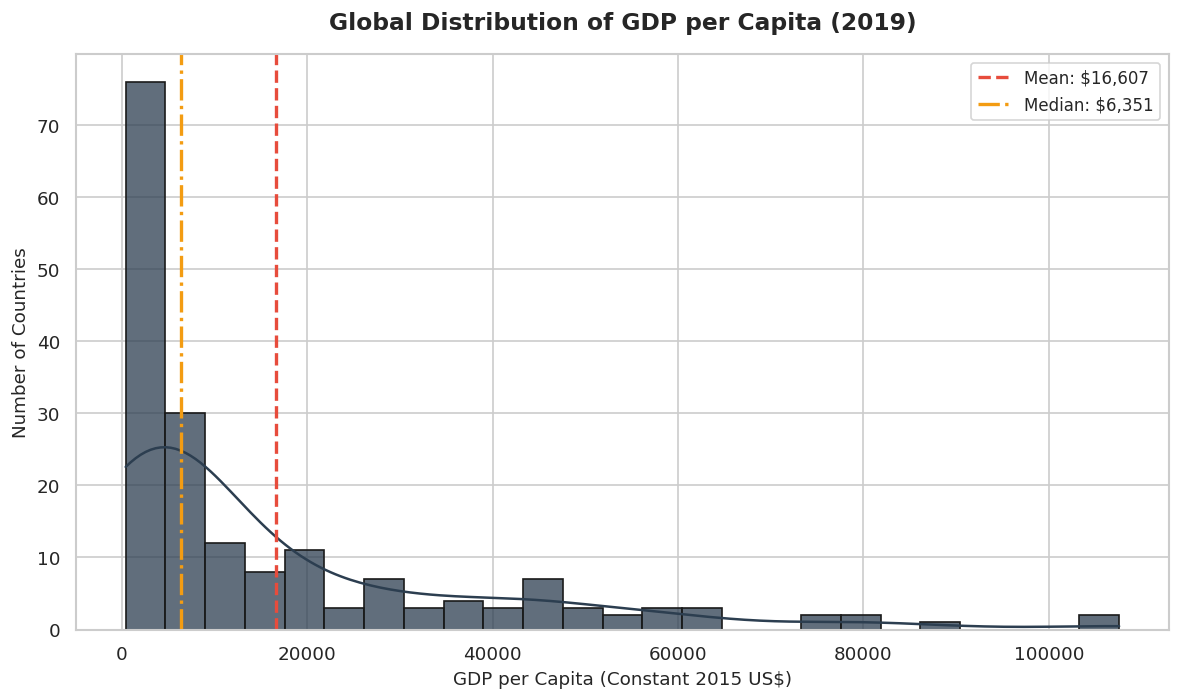

In [159]:
# 1. Standalone GDP per Capita Distribution
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=120)

sns.histplot(wdi_df['gdp_per_capita'], kde=True, color='#2C3E50', bins=25, alpha=0.75, edgecolor='#1A1A1A')
plt.axvline(wdi_df['gdp_per_capita'].mean(), color='#E74C3C', linestyle='--', linewidth=2, label=f"Mean: ${wdi_df['gdp_per_capita'].mean():,.0f}")
plt.axvline(wdi_df['gdp_per_capita'].median(), color='#F39C12', linestyle='-.', linewidth=2, label=f"Median: ${wdi_df['gdp_per_capita'].median():,.0f}")

plt.title('Global Distribution of GDP per Capita (2019)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('GDP per Capita (Constant 2015 US$)', fontsize=11)
plt.ylabel('Number of Countries', fontsize=11)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

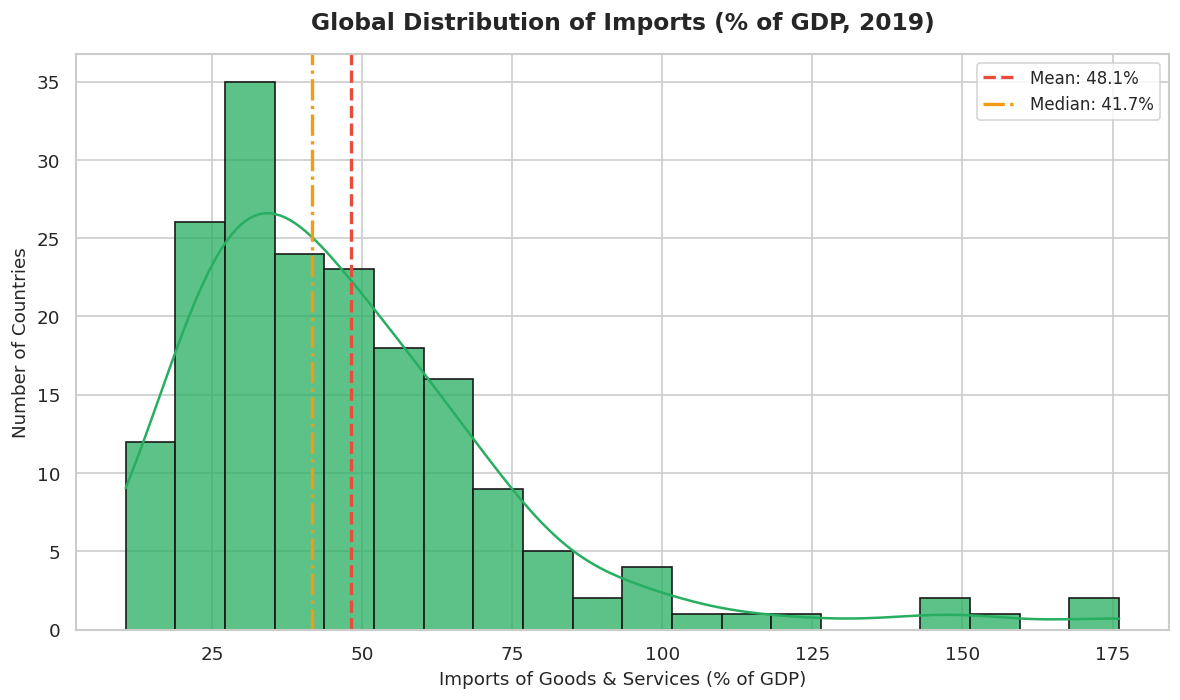

In [160]:
# 2. Standalone Imports Distribution
plt.figure(figsize=(10, 6), dpi=120)

sns.histplot(wdi_df['imports'], kde=True, color='#27AE60', bins=20, alpha=0.75, edgecolor='#1A1A1A')
plt.axvline(wdi_df['imports'].mean(), color='#E74C3C', linestyle='--', linewidth=2, label=f"Mean: {wdi_df['imports'].mean():.1f}%")
plt.axvline(wdi_df['imports'].median(), color='#F39C12', linestyle='-.', linewidth=2, label=f"Median: {wdi_df['imports'].median():.1f}%")

plt.title('Global Distribution of Imports (% of GDP, 2019)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Imports of Goods & Services (% of GDP)', fontsize=11)
plt.ylabel('Number of Countries', fontsize=11)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

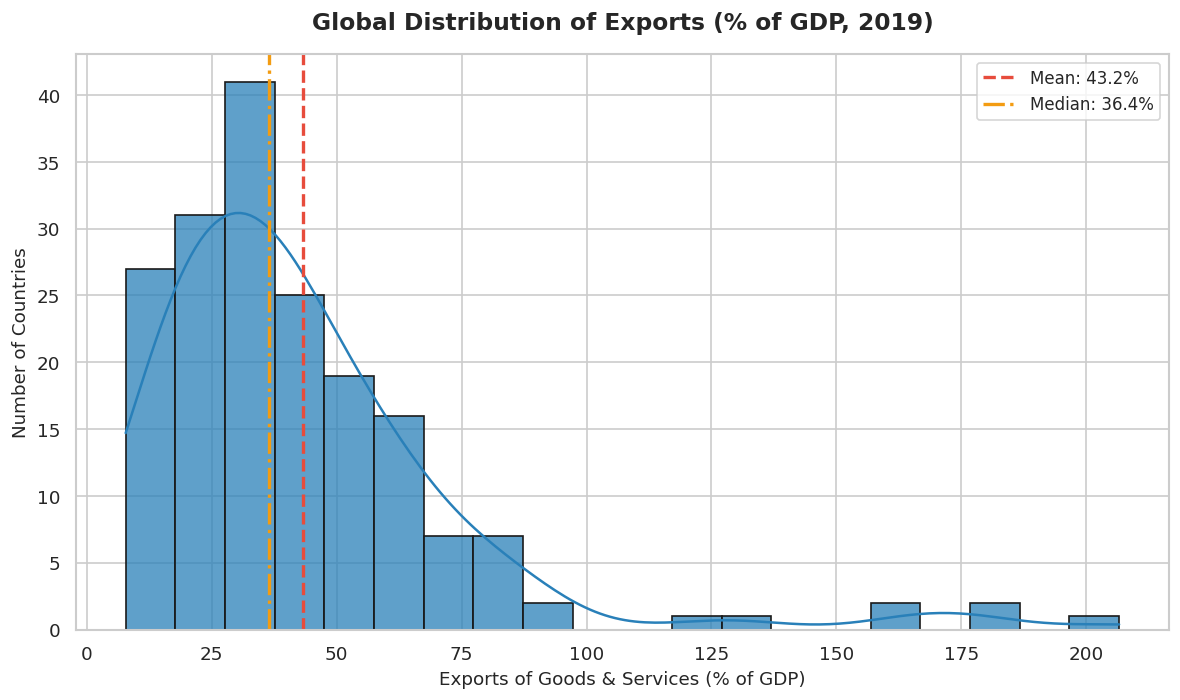

In [161]:
# 3. Standalone Exports Distribution
plt.figure(figsize=(10, 6), dpi=120)

sns.histplot(wdi_df['exports'], kde=True, color='#2980B9', bins=20, alpha=0.75, edgecolor='#1A1A1A')
plt.axvline(wdi_df['exports'].mean(), color='#E74C3C', linestyle='--', linewidth=2, label=f"Mean: {wdi_df['exports'].mean():.1f}%")
plt.axvline(wdi_df['exports'].median(), color='#F39C12', linestyle='-.', linewidth=2, label=f"Median: {wdi_df['exports'].median():.1f}%")

plt.title('Global Distribution of Exports (% of GDP, 2019)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Exports of Goods & Services (% of GDP)', fontsize=11)
plt.ylabel('Number of Countries', fontsize=11)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

In [167]:
# Pearson correlations among indicators
correlations = wdi_df[cols].corr(method='pearson')
print("Pearson Correlations:")
display(correlations)

# Spearman correlations among indicators
spearman_correlations = wdi_df[cols].corr(method='spearman')
print("\nSpearman Correlations:")
display(spearman_correlations)

Pearson Correlations:


,gdp_per_capita,inflation,imports,exports
gdp_per_capita,1.000000,-0.052910,0.271845,0.48434
inflation,-0.052910,1.000000,-0.099238,0.00743
imports,0.271845,-0.099238,1.000000,0.84808
exports,0.484340,0.007430,0.848080,1.00000



Spearman Correlations:


,gdp_per_capita,inflation,imports,exports
gdp_per_capita,1.000000,-0.293972,0.239319,0.549770
inflation,-0.293972,1.000000,-0.223535,-0.309272
imports,0.239319,-0.223535,1.000000,0.721553
exports,0.549770,-0.309272,0.721553,1.000000


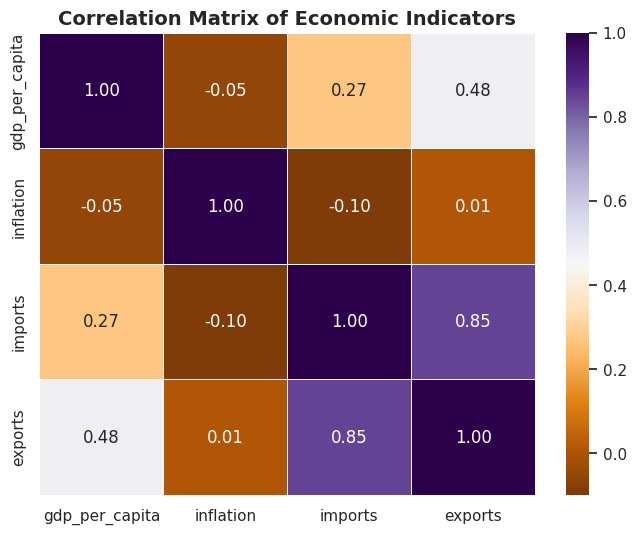

In [166]:
# Create a correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(wdi_df[cols].corr(), annot=True, cmap='PuOr', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Economic Indicators', fontsize=14, fontweight='bold')
plt.show()

####3. Calculate the distance measure using the Mahalanobis distance.
- Explain why you use the Mahalanobis distance over the Euclidean distance. Stata offers some canned programs including one to calcuate the Mahalanobis distance caled mahapick. This doesn't come with the standard installation so you need to first install it.
- The command to compute distance is below:
mahascores gdp_per_cap imports exports, idvar(country) genfile(mahadist) compute_invcov
- This creates a new file called "mahadist" which has all the distance scores.

In [168]:
# Economies at each observed extreme
indicators = ['gdp_per_capita', 'inflation', 'imports', 'exports']

extremes = []
for col in indicators:
    # Find the row with the minimum value for this indicator
    min_row = wdi_df.loc[wdi_df[col].idxmin()]
    # Find the row with the maximum value for this indicator
    max_row = wdi_df.loc[wdi_df[col].idxmax()]

    extremes.append({
        'Indicator': col,
        'Min Country': min_row['country'],
        'Min Value': min_row[col],
        'Max Country': max_row['country'],
        'Max Value': max_row[col]
    })

extremes_df = pd.DataFrame(extremes)
display(extremes_df)

,Indicator,Min Country,Min Value,Max Country,Max Value
0,gdp_per_capita,Central African Republic,401.825822,Luxembourg,107591.899505
1,inflation,Naoero,-4.603271,"Venezuela, RB",21909.342668
2,imports,Cuba,10.607517,"Hong Kong SAR, China",176.092206
3,exports,Nepal,7.779936,Luxembourg,206.580146


Mahalanobis Distance

In [169]:
# 1. Select the indicators to use for distance calculation
features = ['gdp_per_capita', 'inflation', 'imports', 'exports']

# 2. Filter out rows that have NaN values in our key features
wdi_clean = wdi_df.dropna(subset=features).copy()

# 3. Extract values and compute the inverse covariance matrix
x = wdi_clean[features].values
cov_matrix = np.cov(x, rowvar=False)
inv_cov_matrix = np.linalg.inv(cov_matrix)

# 4. Locate the vector for the United States
us_row = wdi_clean[wdi_clean['country'] == 'United States']
if us_row.empty:
    us_row = wdi_clean[wdi_clean['country'].str.contains('United States', case=False, na=False)]

us_vector = us_row[features].values[0]

# 5. Calculate Mahalanobis distance from US to each country
mahalanobis_distances = []
for idx, row in wdi_clean.iterrows():
    country_vector = row[features].values
    # Calculate distance
    d = distance.mahalanobis(us_vector, country_vector, inv_cov_matrix)
    mahalanobis_distances.append(d)

# Add distance scores to the cleaned dataframe
wdi_clean['mahalanobis_distance'] = mahalanobis_distances

# Save the result back to wdi_df
wdi_df = wdi_clean

# Show the dataframe sorted by distance to find the closest countries to the US
print("Mahalanobis distances successfully calculated (non-NaN)!")
display(wdi_df.sort_values(by='mahalanobis_distance').head(10))

Mahalanobis distances successfully calculated (non-NaN)!


,country,exports,gdp_per_capita,imports,inflation,mahalanobis_distance
206,United States,11.789197,61047.964824,14.469283,1.650466,0.000000
10,Australia,24.062480,59181.299790,21.939203,3.476600,0.557496
147,Norway,35.695052,79937.509789,33.185191,-0.477791,0.979035
205,United Kingdom,31.902860,47866.914035,33.100706,2.461330,1.237178
88,Iceland,44.713862,57118.845278,39.078504,4.836789,1.344622
35,Canada,32.352626,45100.336806,33.818716,1.546199,1.380437
98,Japan,17.037797,36837.258365,17.320500,0.782577,1.490063
141,New Zealand,27.320284,40615.726695,27.140962,3.299628,1.498499
187,Sweden,48.288658,53024.409949,44.462481,2.425887,1.589507
159,Qatar,52.188860,63430.460761,37.857516,-4.455914,1.592003


####4. Summarize the Mahalanobis distance measure between the United States and other countries in the world.
Which 3 countries does the United States have the smallest distance and largest distance with?

* Use the "keep if" command to restrict the above data for just distance between US and all other countries.


In [128]:
# Filter out the US itself to find the closest countries
non_us_df = wdi_df[wdi_df['country'] != 'United States']

# Get the 5 closest countries
closest_5 = non_us_df.sort_values(by='mahalanobis_distance').head(5)

# Get the 5 furthest countries
furthest_5 = non_us_df.sort_values(by='mahalanobis_distance', ascending=False).head(5)

print("=== Top 5 Countries Closest to the United States ===")
display(closest_5[['country', 'gdp_per_capita', 'inflation', 'imports', 'exports', 'mahalanobis_distance']])

print("\n=== Top 5 Countries Furthest from the United States ===")
display(furthest_5[['country', 'gdp_per_capita', 'inflation', 'imports', 'exports', 'mahalanobis_distance']])

=== Top 5 Countries Closest to the United States ===


,country,gdp_per_capita,inflation,imports,exports,mahalanobis_distance
10,Australia,59181.299790,3.476600,21.939203,24.062480,0.557496
147,Norway,79937.509789,-0.477791,33.185191,35.695052,0.979035
205,United Kingdom,47866.914035,2.461330,33.100706,31.902860,1.237178
88,Iceland,57118.845278,4.836789,39.078504,44.713862,1.344622
35,Canada,45100.336806,1.546199,33.818716,32.352626,1.380437



=== Top 5 Countries Furthest from the United States ===


,country,gdp_per_capita,inflation,imports,exports,mahalanobis_distance
210,"Venezuela, RB",1759.055474,21909.342668,10.933114,47.195726,13.837835
54,Djibouti,2781.943501,0.449845,154.221366,166.717864,7.625096
86,"Hong Kong SAR, China",44195.274114,2.044955,176.092206,177.651315,6.589756
116,Luxembourg,107591.899505,0.916369,176.080635,206.580146,6.266985
164,San Marino,43525.403980,0.914095,143.267534,163.997237,6.034089
